In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
import scipy.constants as pc
import astropy.units as u
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.table import Table
from astropy.table import vstack
from astropy.cosmology import FlatLambdaCDM
from scipy.stats import ttest_rel
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import AutoMinorLocator
import os
from matplotlib.gridspec import GridSpec
import h5py
import emcee
import corner

FIG_DIR = "/raid/scratch/work/alberttg/Masters_project/Plots"

DATA_PRODUCTS_PATH = "/raid/scratch/work/alberttg/Masters_project/Data_products"

POSTERIOR_PATH = '/raid/scratch/work/austind/GALFIND_WORK/Bagpipes/pipes/posterior'

In [2]:
def gaussian_function(x, sigma, mu, amp):
    """
    1D Gaussian for a histogram density plot. The amplitude is dependent on sigma.
    """

    y = (amp / np.pi) * (0.5 * sigma) / ((x - mu)**2 + (0.5 * sigma)**2)

    return y

In [ ]:
def _parse_err(err, n):
    """
    Normalize an error specification into (err_lo, err_hi) arrays of length n.

    Accepted forms for `err`:
      - None                            -> zeros (no error)
      - scalar or 1D array of length n  -> symmetric error (same as before)
      - [err_high, err_low]             -> asymmetric error; each of
        err_high/err_low can be a scalar (applied to all points) or a
        length-n array (per-point)

    Returned lo/hi are positive distances from the central value
    (lower bound = value - lo, upper bound = value + hi).
    """
    if err is None:
        return np.zeros(n), np.zeros(n)

    # Asymmetric: [err_high, err_low]
    if isinstance(err, (list, tuple)) and len(err) == 2:
        hi = np.asarray(err[0], dtype=float) 
        lo = np.asarray(err[1], dtype=float)
        if hi.ndim == 0:
            hi = np.full(n, float(hi))
        if lo.ndim == 0:
            lo = np.full(n, float(lo))
        return lo.copy(), hi.copy()

    # Symmetric: scalar or array, same as before
    arr = np.asarray(err, dtype=float)
    if arr.ndim == 0:
        arr = np.full(n, float(arr))
    return arr.copy(), arr.copy()


def fit_gaussian_mcmc(x_in, y_in, x_err=None, y_err=None, x_pivot=None,
                     n_walkers=32, n_steps=5000, plot=True, save_path=None):
    """
    Bayesian gaussian fit without intrinsic scatter,
    supporting asymmetric measurement errors in both x and y (but we have none here).

    x_err / y_err each accept:
      - None, a scalar, or a 1D array of length N (symmetric errors, same
        as before), OR
      - [err_high, err_low] for asymmetric errors, where each of
        err_high/err_low is a scalar (applied to every point) or a
        length-N array (per-point).

    Asymmetric-error handling
    --------------------------
    Each data point's error distribution is modeled as a split-normal
    (two-piece Gaussian): width `sigma_lo` below the measured value and
    `sigma_hi` above it. At every MCMC step, for each point we compare the
    model prediction to the data (delta = model - data) and pick the
    error side consistent with that comparison:
        delta >= 0  ->  use the "hi" error (model sits above the data)
        delta <  0  ->  use the "lo" error (model sits below the data)
    This is applied to both the y errors and the x errors (the latter
    projected into y-space via the slope, m^2 * xerr^2, as in the
    symmetric case). This is the standard practical approximation for
    asymmetric errors in a likelihood — it is exact only when the true
    error distribution really is split-normal, but works well in general
    and reduces to the ordinary symmetric-error likelihood when lo == hi.
    The intrinsic scatter term sigma_int is kept symmetric.
    """
    # --- Step 1: Data Cleaning & Pivot Handling ---
    x = np.asarray(x_in, dtype=float)
    y = np.asarray(y_in, dtype=float)
    n = len(x)

    xe_lo, xe_hi = _parse_err(x_err, n)
    ye_lo, ye_hi = _parse_err(y_err, n)
    # xe_lo = np.zeros(n)
    # xe_hi = np.zeros(n)
    # ye_lo = np.zeros(n)
    # ye_hi = np.zeros(n)
    # My basic version of _parse_err function 

    xp = 0.0 if x_pivot is None else x_pivot
    
    mask = (
        np.isfinite(x) & np.isfinite(y)
        & np.isfinite(xe_lo) & np.isfinite(xe_hi)
        & np.isfinite(ye_lo) & np.isfinite(ye_hi)
    )

    x, y = x[mask], y[mask]
    xe_lo, xe_hi = xe_lo[mask], xe_hi[mask]
    ye_lo, ye_hi = ye_lo[mask], ye_hi[mask]
    n = len(x)

    # Guard against zero/negative error entries (keeps likelihood well-defined)
    xe_lo = np.where(xe_lo <= 0, 1e-10, xe_lo)
    xe_hi = np.where(xe_hi <= 0, 1e-10, xe_hi)
    ye_lo = np.where(ye_lo <= 0, 1e-10, ye_lo)
    ye_hi = np.where(ye_hi <= 0, 1e-10, ye_hi)

    #print(xe_lo)
    #print(xe_hi)
    #print(ye_lo)
    #print(ye_hi)

    if len(x) < 2:
        raise ValueError("Not enough finite data points.")

    # --- Step 2: Robust Initial Guess ---
    try:
        popt, pcov = curve_fit(gaussian_function, x - xp, y, p0=[np.std(x-xp), np.mean(x-xp), np.max(y)])
        guess_sig, guess_mu, guess_amp = popt
        print(f"Guesses: sig = {guess_sig:.3f}, mean = {guess_mu:.3f}, amp = {guess_amp:.3f}")
    
    except np.linalg.LinAlgError:
        guess_sig, guess_mu, guess_amp = np.std(x-xp), np.mean(x-xp), np.max(y)

    # guess_std = np.std(y - gaussian_function(x-xp, guess_sig, guess_mu, guess_amp))

    # --- Step 3: MCMC Functions (3 parameters: m, c, sigma_int) ---
    def log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        sig, mu, amp = theta
        # if sigma_int <= 0: this was one of the params
        #    return -np.inf

        model = gaussian_function(x, sig, mu, amp)
        delta = model - y  # positive => model above data

        y_err = np.where(delta >= 0, yerr_hi, yerr_lo)
        x_err = np.where(delta >= 0, xerr_hi, xerr_lo)

        n = len(x) # no. of data points

        ln_L = -0.5 * np.sum(np.log(2 * np.pi * y_err**2)) - 0.5 * np.sum(((y - model) / y_err)**2)
        # ln_L = - (n/2) * np.log(2*np.pi) - n * np.log(sig) - 0.5 * np.sum( ((delta - mu)  / sig)**2)

        return ln_L

    # Set prior limits safely outside empirical distribution boundaries
    min_sig, max_sig = 1e-4, guess_sig * 3.0
    min_mu, max_mu = guess_mu - (3 * guess_sig), guess_mu + (3 * guess_sig)
    min_amp, max_amp = 0, guess_amp * 2.0 # empirical uniform prior

    def log_prior(theta): 
        """
        Uses flat uniform prior.
        """
        sig, mu, amp = theta
        if min_sig < sig < max_sig and min_mu < mu < max_mu and min_amp < amp < max_amp:
            return 0 # This is return 0 for flat uniform prior
        return -np.inf

    def log_probability(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        ll = log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp)
        return lp + ll if np.isfinite(ll) else -np.inf

    # --- Step 4: Run MCMC ---
    ndim = 3
    # initial = np.array([guess_sig, guess_mu, guess_amp if guess_std > 0 else 0.1]) old
    initial = np.array([guess_sig, guess_mu, guess_amp])
    pos = initial + 1e-4 * np.random.randn(n_walkers, ndim)

    sampler = emcee.EnsembleSampler(
        n_walkers, ndim, log_probability,
        args=(x, y, xe_lo, xe_hi, ye_lo, ye_hi, xp)
    )
    sampler.run_mcmc(pos, n_steps, progress=True)

    flat_samples = sampler.get_chain(discard=1000, thin=15, flat=True)

    x_range = np.linspace(x.min(), x.max(), 100)
    sig_samples = flat_samples[:, 0]
    mu_samples = flat_samples[:, 1]
    amp_samples = flat_samples[:, 2]
    # ------------------------------------------------------ intrinsic scatter was a parameter here but we are fitting to a histogram

    models = gaussian_function((x_range - xp), sig_samples[:, np.newaxis], mu_samples[:, np.newaxis], amp_samples[:, np.newaxis])

    sig_med, mu_med, amp_med = np.median(flat_samples, axis=0)
    lower_bound = np.percentile(models, 16, axis=0)
    upper_bound = np.percentile(models, 84, axis=0)

    # --- Step 5: Visualization ---
    if plot:
        """
        plt.figure(figsize=(8, 6))
        print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")

        # matplotlib expects asymmetric errors as [lower_distances, upper_distances]
        # ax.errorbar(x, y, xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi], fmt=".k", alpha=0.4, label="Data", zorder=1)
        
        plt.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
        plt.plot(x_range, gaussian_function((x_range - xp), sig_med, mu_med), color="darkblue", lw=2, label="Median Fit")
        plt.legend()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.show()
        """

        labels = [r"Sigma $\sigma$", f"Mean $\mu$ (at $x={xp}$)", "Amplitude"]
        corner.corner(flat_samples, labels=labels, truths=[sig_med, mu_med, amp_med], show_titles=True)
        plt.show()

    results = {
        "sigma_median": sig_med,
        "mean_median": mu_med,
        "amplitude": amp_med,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "sig_16": np.percentile(flat_samples[:, 0], 16),
        "sig_84": np.percentile(flat_samples[:, 0], 84),
        "mu_16": np.percentile(flat_samples[:, 1], 16),
        "mu_84": np.percentile(flat_samples[:, 1], 84),
        "amp_16": np.percentile(flat_samples[:, 2], 16),
        "amp_84": np.percentile(flat_samples[:, 2], 84),
        "x_pivot": xp,
        "x_range": x_range,
    }

    return results

In [4]:
def get_posterior(sample_table, SFH_model):
    """
    Finding the paths to the stellar mass posterior, based on galaxy survey id, survey and SFH model used in BAGPIPES.
    Each galaxy has its own posterior.
    """

    surveys = np.asarray(sample_table["SURVEY"].data, dtype=str)

    survey_ids = np.asarray(sample_table["#ID"].data, dtype=int)

    redshifts = np.asarray(sample_table["input_redshift"].data, dtype=float)

    mass = np.asarray(sample_table["stellar_mass_50"].data, dtype=float)

    src_corr = np.asarray(sample_table["ext_src_corr_0.32as_F444W"].data, dtype=float)

    posteriors = []

    for i in range(len(sample_table)):

        gal_id = survey_ids[i]
        survey = surveys[i]
        redshift = redshifts[i]
        corr = src_corr[i]

        if survey in ["CEERSP1", "CEERSP2", "CEERSP3", "CEERSP4", "CEERSP5", "CEERSP6", "CEERSP7", "CEERSP8", "CEERSP9", "CEERSP10", "NEP-1", "NEP-2", "NEP-3", "NEP-4", "NGDEEP"]:

            path = os.path.join(POSTERIOR_PATH, f"v14_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")

        elif survey in ["PRIMER-COSMOS","PRIMER-UDS"]:
                
            path = os.path.join(POSTERIOR_PATH, f"v12_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")


        elif survey in ["JADES-DR3-GS-East", "JADES-DR3-GS-North", "JADES-DR3-GS-South", "JADES-DR3-GS-West", "JADES-DR3-GN-Parallel", "JADES-DR3-GN-Medium", "JADES-DR3-GN-Deep"]:

            path = os.path.join(POSTERIOR_PATH, f"v13_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")
            
        else:
            print(f"Galaxy {gal_id} could not be found in these surveys")
            print(f"Check survey {survey}")
            continue


        with h5py.File(path,'r') as hf:
            # Print all root level object names (aka keys) 
            # these can be group or dataset names 
            # print("Keys: %s" % hf['basic_quantities'].keys())
            # print("Keys: %s" % hf['advanced_quantities'].keys())
            stellar_mass = hf['basic_quantities']['stellar_mass'][:]
            
        stellar_mass = stellar_mass * corr
        median_mass = np.median(stellar_mass)
        log_mass = np.array(stellar_mass - median_mass)

        if len(log_mass) != 500:
            print("Length not 500: ", len(log_mass))
            print(f"Check the posterior of galaxy {gal_id} in survey {survey} ")

        posteriors.append(log_mass) # ought to be in same order as mass and redshift are ordered, which is by ith row of sample table

    # print(posteriors)
    
    plot_binned_posterior(mass, redshifts, posteriors, 50) # I think the posterior are in the same order as galaxy table (mass, redshift...)

    

In [5]:
def plot_binned_posterior(mass, redshift, posterior, histogram_bins):
    """
    Sorting the posterior into bins, selected by mass and redshift value.

    mass : array of floats
        The mass values of all the galaxies
    redshift : array of floats
        The zfix redshift values of all the galaxies
    posterior : array of arrays of floats
        The posterior for each galaxy, which are each an array.
    histogram_bins : float
        Number of histogram bins for each plot and also for gaussian fitting
    """
    z_bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 10.5], [10.5, 11.5], [11.5, 13.5]]
    # z_bins = [[6.5, 7.5], [7.5, 8.5], [9.5, 10.5], [10.5, 13.5]]

    fig, axes = plt.subplots(3, 6, figsize=(30,20), constrained_layout=True)
    # Starting binning, bin by mass first (vertical bins)
    # mass_bins = np.linspace(mass.min(), mass.max(), n_mass_bins + 1)
    # mass_bins = [[mass_bins[i], mass_bins[i + 1]] for i in range(len(mass_bins) - 1)]
    # mass_bins.reverse()
    #print("Mass bins: ", mass_bins)
    mass_bins = [[9,11], [7,9], [6,7]] # Have put them in reverse for the gridspec plotting

    for i in range(len(mass_bins)):
        
        bin_width = mass_bins[i][1] - mass_bins[i][0]

        mass_bin_mask = (mass >= mass_bins[i][0]) & (mass < mass_bins[i][1]) # Splitting into mass bins

        redshift_m_binned = redshift[mass_bin_mask]
        mass_errors_m_binned = mass[mass_bin_mask]
        
        posterior_m_binned = [item for item, m in zip(posterior, mass_bin_mask) if m]


        # Now bin by z (horizontal bins)
        for j in range(len(z_bins)):
            
            z_bin_mask = (redshift_m_binned >= z_bins[j][0]) & (redshift_m_binned < z_bins[j][1])

            redshift_z_binned = redshift_m_binned[z_bin_mask]
            mass_z_binned = mass_errors_m_binned[z_bin_mask] # x axis values now binned by z and mass

            print("m bin: ", mass_bins[i])
            print("z bin: ", z_bins[j])
            print("Number of gals in bin: ", len(redshift_z_binned))

            posterior_z_binned = [item for item, m in zip(posterior_m_binned, z_bin_mask) if m]

            # [print(len(p)) for p in posterior_z_binned] # this checks that most posterior are length 500, but one is 106 and one is 107

            if len(posterior_z_binned) == 0:
                continue  # or leave the axis empty

            # --------------------------- binning complete ----------------------------
            # Now calculating posterior sum and making into a normalised histogram

            posterior_sum = np.concatenate(posterior_z_binned, axis=0)  # was trying this to see combined distribution of mass offsets for the galaxies in a bin
            # posterior_sum = [sum(p) for p in zip(*posterior_z_binned)] # idk about this one...
            # print("sum shape: ", np.shape(posterior_sum))
            
            raw_counts, edges = np.histogram(posterior_sum, bins=histogram_bins)
            centres = 0.5 * (edges[1:] + edges[:-1])
            yerr = np.sqrt(np.maximum(raw_counts, 1)) # Poisson errors on hist density

            # Calculate the normalization factor used by density=True
            bin_widths = np.diff(edges)
            total_counts = len(posterior_sum)
            normalization = total_counts * bin_widths

            # Calculate density and its corresponding scaled error
            counts = raw_counts / normalization
            # Apply Poisson error on raw counts, safely handling zero-bins with np.maximum
            yerr = np.sqrt(np.maximum(raw_counts, 1)) / normalization
            # print("yerr :", yerr)
            # print("x : ", centres)
            # print("y : ", counts)

            results = fit_gaussian_mcmc(centres, counts, x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True)

            sig_med = results["sigma_median"]
            mu_med = results["mean_median"]
            amp_med = results["amplitude"]
            x_range = results["x_range"]
            x_pivot = results["x_pivot"]
            lower_bound = results["lower_bound"]
            upper_bound = results["upper_bound"]

            # ----------------------------------- Plotting ------------------------------------
            
            ax = axes[i,j]
                    
            # ax.set_ylabel(r'Probability density \left( $\sigma_{M_\star}^{-1}$ \right)', fontsize=16)
            if j == 0:
                ax.set_ylabel(rf"${mass_bins[i][0]} ≤ \log_{10}(M_\star/M_\odot) < {mass_bins[i][1]}$", fontsize=16)
            
            ax.grid(True)

            #plt.figure(figsize=(8, 6))
            print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")
    
            # ax.errorbar(x, y, xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi], fmt=".k", alpha=0.4, label="Data", zorder=1)
            
            ax.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
            ax.plot(x_range, gaussian_function((x_range - x_pivot), sig_med, mu_med, amp_med), color="darkblue", lw=2, label="Median Fit")
            ax.legend(fontsize=14)

            ax.tick_params(
                    axis="both",
                    which="major",
                    labelsize=14,
                    length=8,
                    width=1.5,
                    direction="in",
                    top=True,
                    right=True
                    )
            
            ax.xaxis.set_minor_locator(AutoMinorLocator(5))
            ax.yaxis.set_minor_locator(AutoMinorLocator(5))

            ax.tick_params(
                    axis="both",
                    which="minor",
                    length=4,
                    width=1,
                    direction="in",
                    top=True,
                    right=True
                    )

            ax.hist(posterior_sum, bins=histogram_bins, color='steelblue', density=True) # Try to normalise????
            #N = len(mass_errors_binned)

            legend_text = rf"${z_bins[j][0]} ≤ z < {z_bins[j][1]}$"
            ax.text(0.6, 0.95, legend_text, transform=ax.transAxes, fontsize=15, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    fig.supylabel(r'Histogram density', fontsize=19)
    fig.supxlabel(r'Stellar Mass $\log_{10}(M_\star/M_\odot) - \langle( \log_{10}(M_\star/M_\odot) \rangle $', fontsize=19)
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "gridspec_mass_errors.png")
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


Length not 500:  106
Check the posterior of galaxy 11825 in survey NEP-4 
Length not 500:  117
Check the posterior of galaxy 96942 in survey PRIMER-UDS 
m bin:  [9, 11]
z bin:  [6.5, 7.5]
Number of gals in bin:  50
Guesses: sig = 0.116, mean = 0.006, amp = 1.066


100%|██████████| 5000/5000 [00:05<00:00, 840.54it/s]


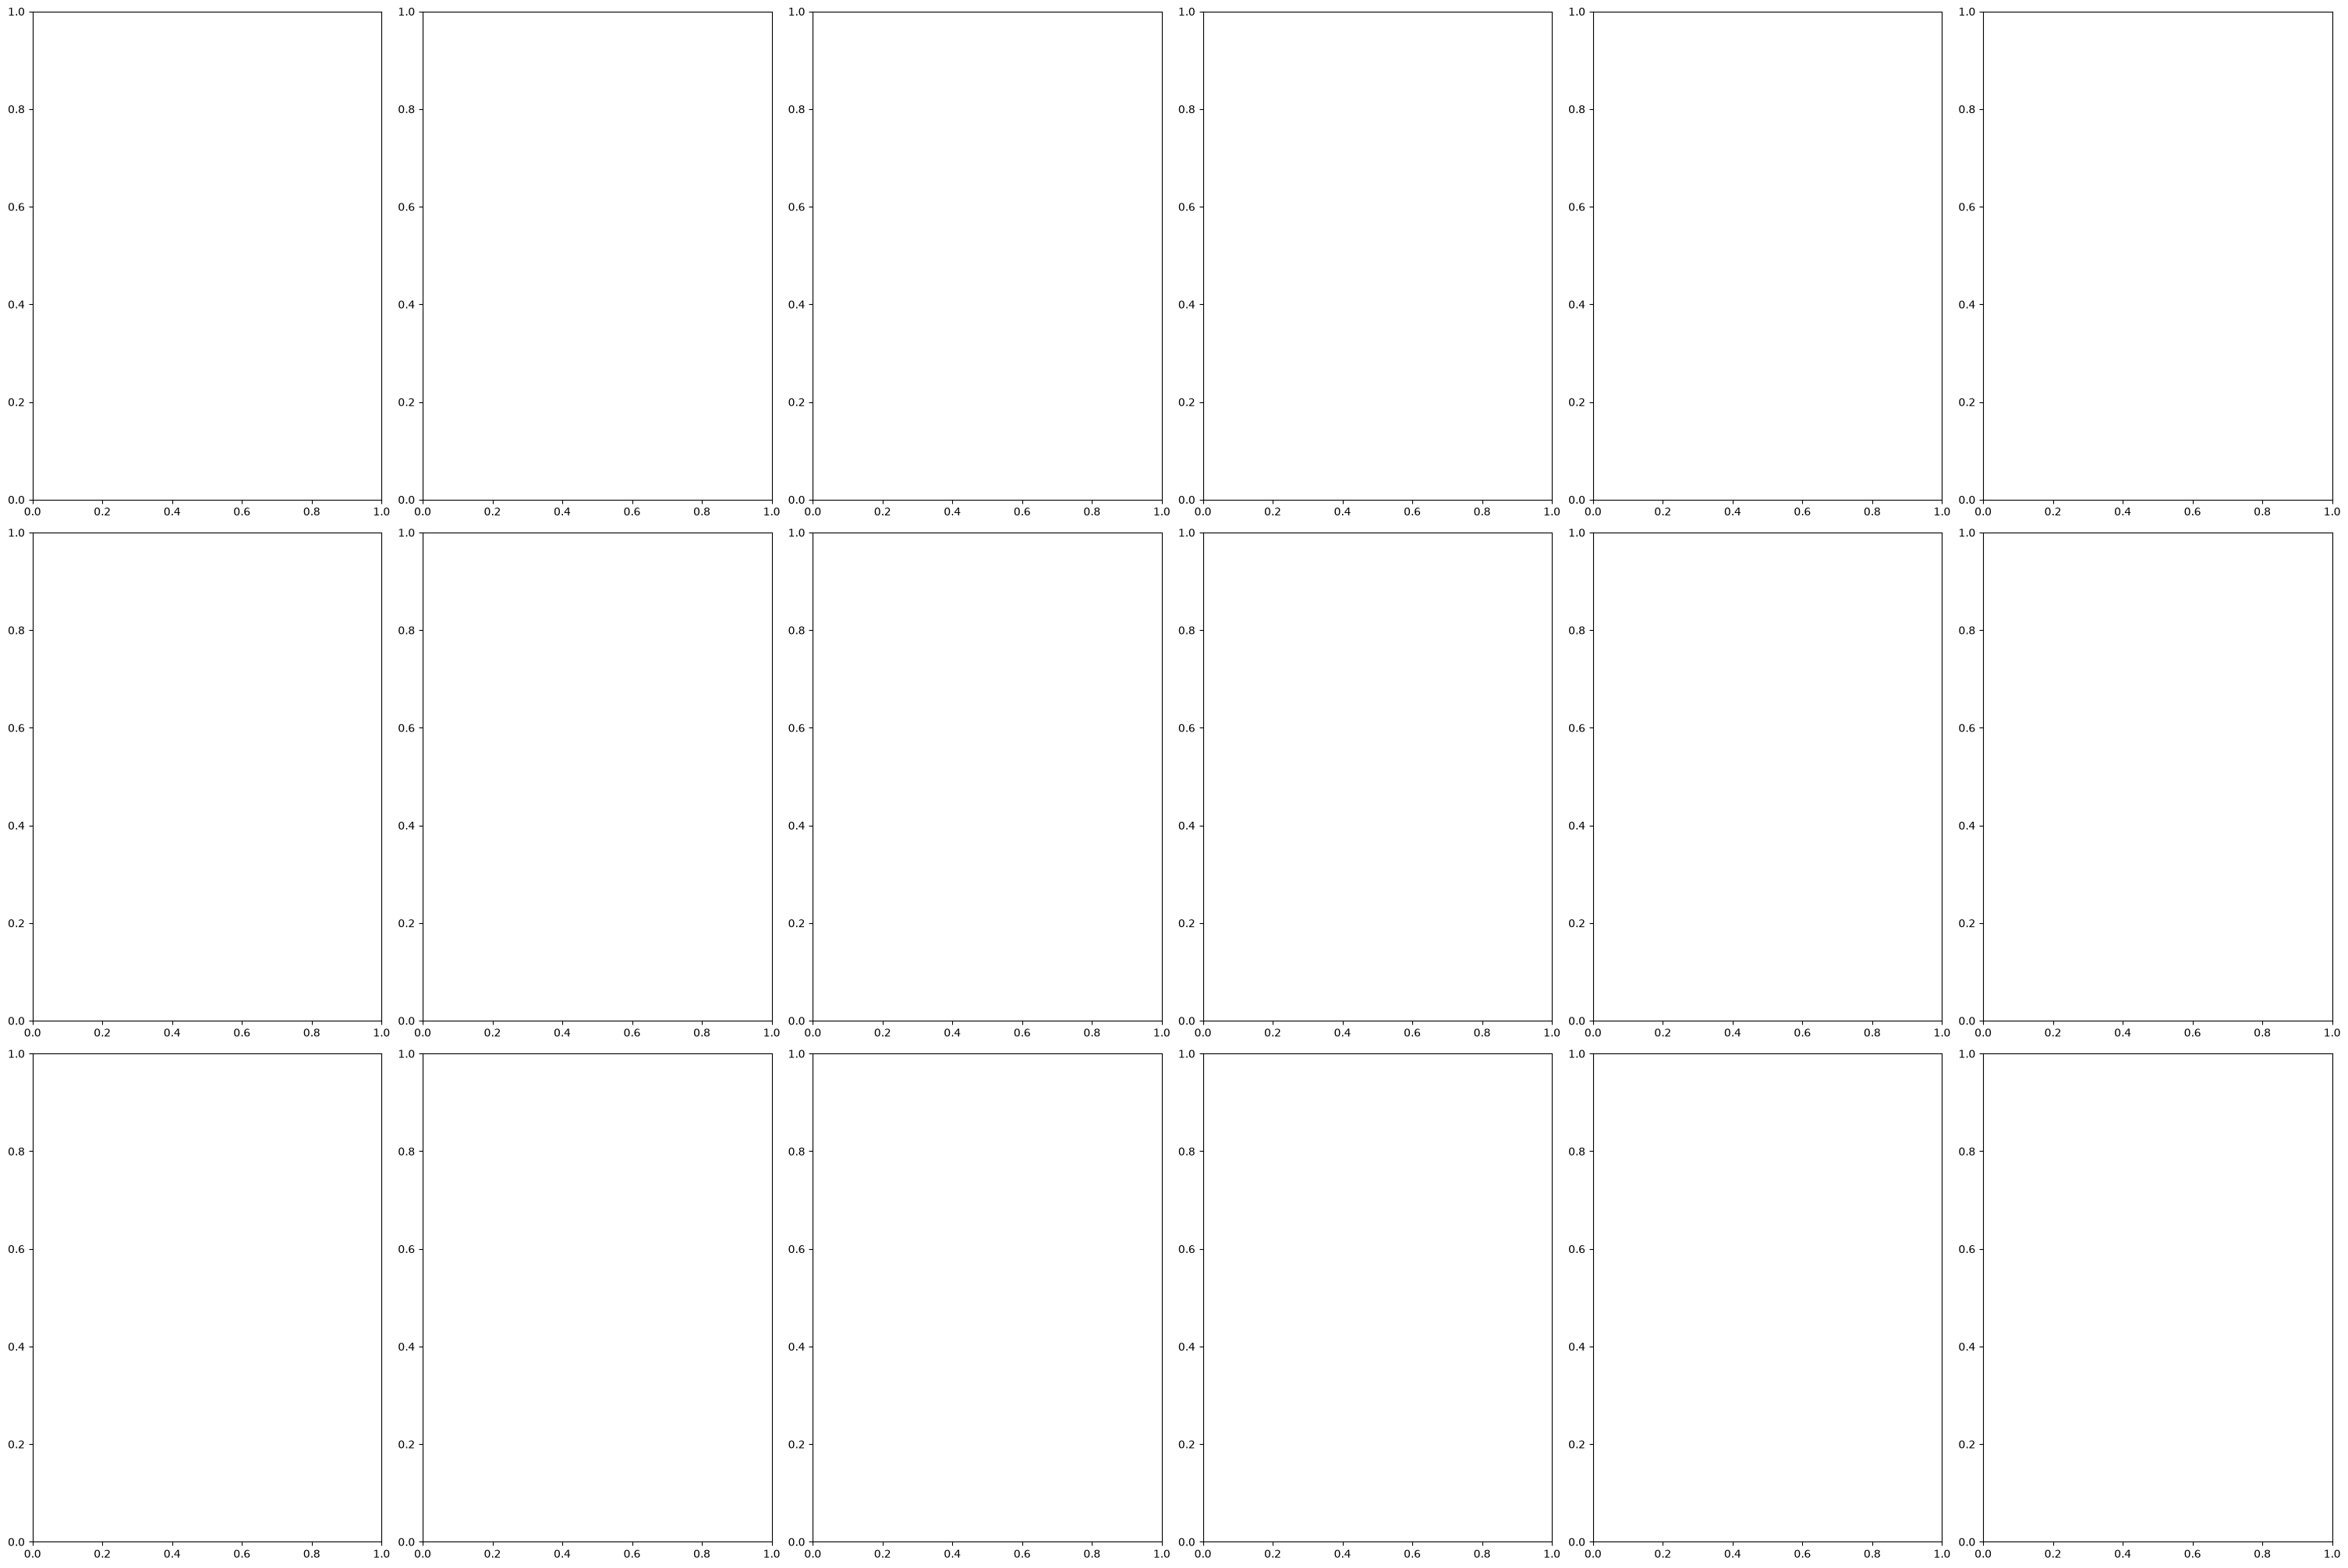

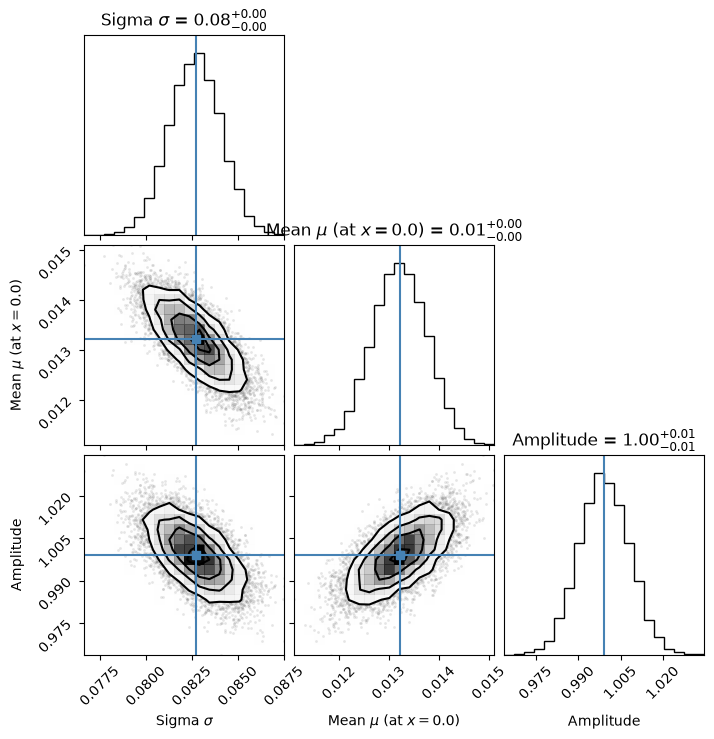

Median sigma: 0.083, mean: 0.013, amplitude: 0.999
m bin:  [9, 11]
z bin:  [7.5, 8.5]
Number of gals in bin:  10
Guesses: sig = 0.119, mean = 0.003, amp = 1.029


100%|██████████| 5000/5000 [00:05<00:00, 847.95it/s]


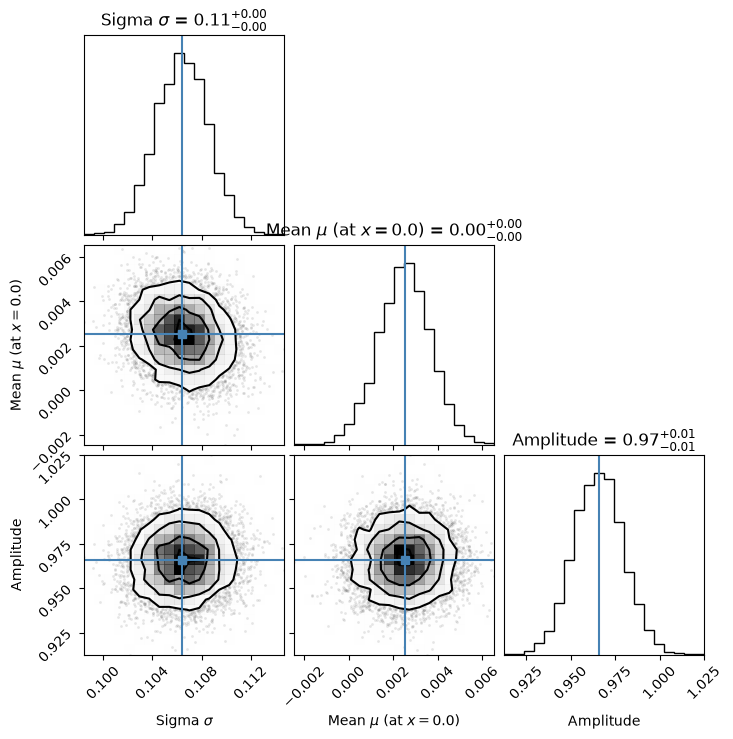

Median sigma: 0.106, mean: 0.003, amplitude: 0.966
m bin:  [9, 11]
z bin:  [8.5, 9.5]
Number of gals in bin:  6
Guesses: sig = 0.081, mean = 0.002, amp = 1.100


100%|██████████| 5000/5000 [00:06<00:00, 763.98it/s]


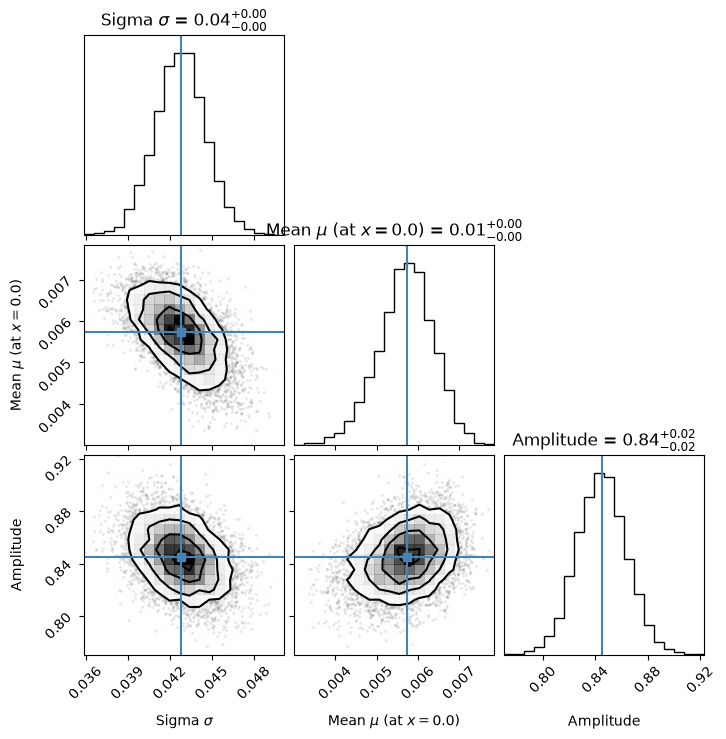

Median sigma: 0.043, mean: 0.006, amplitude: 0.845
m bin:  [9, 11]
z bin:  [9.5, 10.5]
Number of gals in bin:  5
Guesses: sig = 0.092, mean = 0.007, amp = 1.030


100%|██████████| 5000/5000 [00:07<00:00, 701.86it/s]


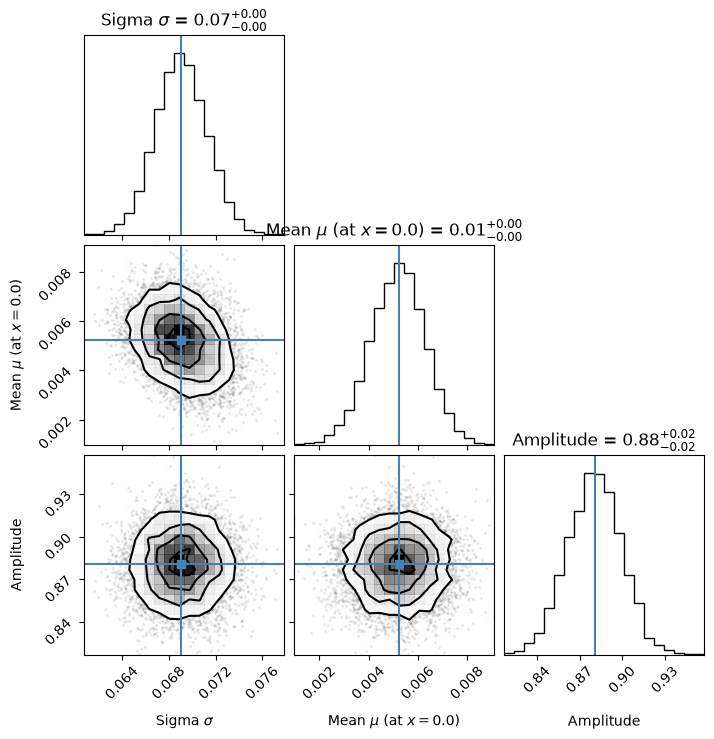

Median sigma: 0.069, mean: 0.005, amplitude: 0.881
m bin:  [9, 11]
z bin:  [10.5, 11.5]
Number of gals in bin:  14
Guesses: sig = 0.182, mean = 0.015, amp = 1.052


100%|██████████| 5000/5000 [00:06<00:00, 732.57it/s]


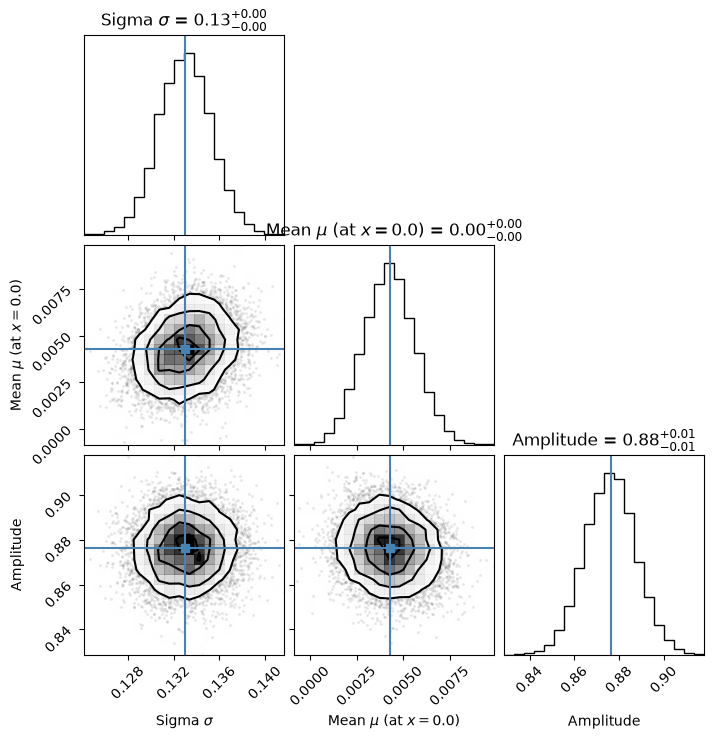

Median sigma: 0.133, mean: 0.004, amplitude: 0.876
m bin:  [9, 11]
z bin:  [11.5, 13.5]
Number of gals in bin:  15
Guesses: sig = 0.383, mean = 0.039, amp = 0.965


100%|██████████| 5000/5000 [00:06<00:00, 754.95it/s]


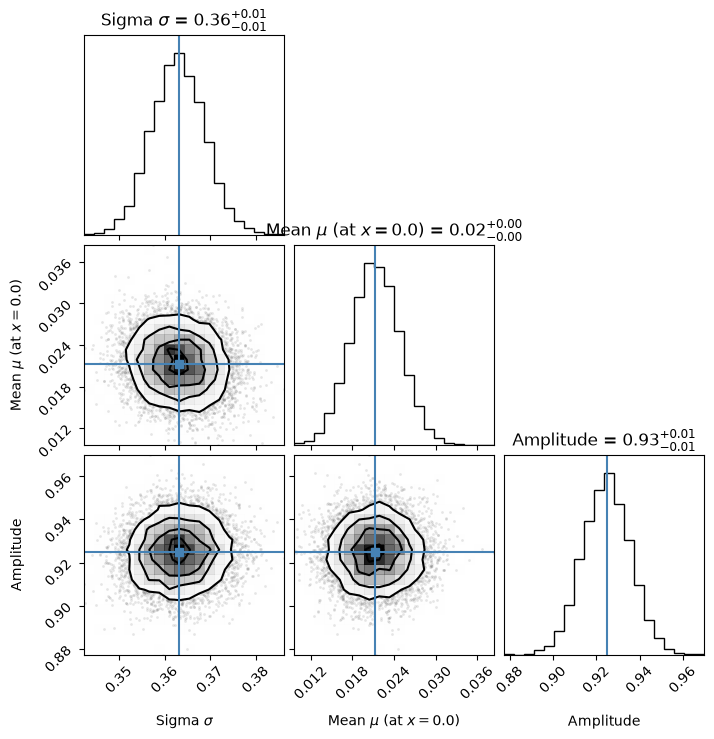

Median sigma: 0.363, mean: 0.021, amplitude: 0.925
m bin:  [7, 9]
z bin:  [6.5, 7.5]
Number of gals in bin:  1066
Guesses: sig = 0.149, mean = 0.086, amp = 1.686


100%|██████████| 5000/5000 [00:06<00:00, 786.42it/s]


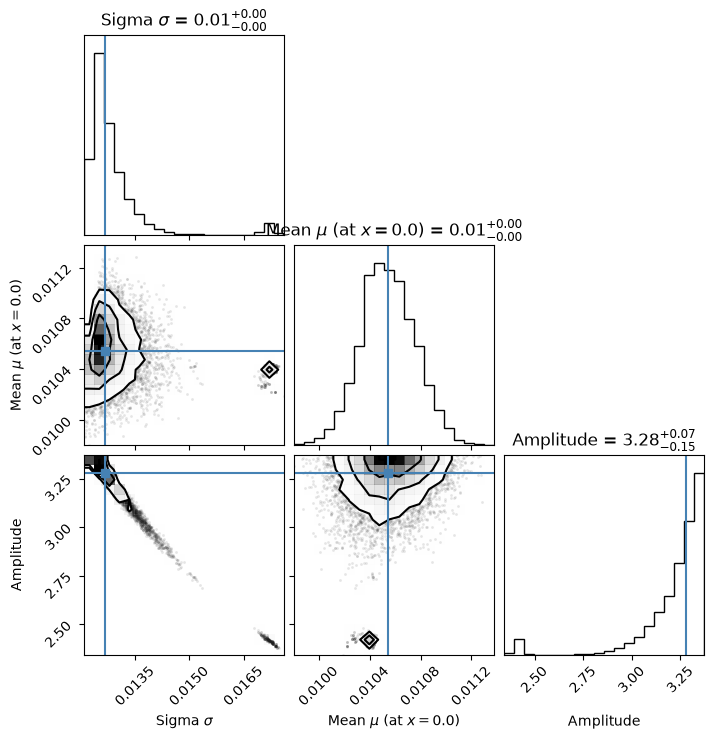

Median sigma: 0.013, mean: 0.011, amplitude: 3.278
m bin:  [7, 9]
z bin:  [7.5, 8.5]
Number of gals in bin:  484
Guesses: sig = 0.269, mean = -0.011, amp = 1.097


100%|██████████| 5000/5000 [00:07<00:00, 691.36it/s]


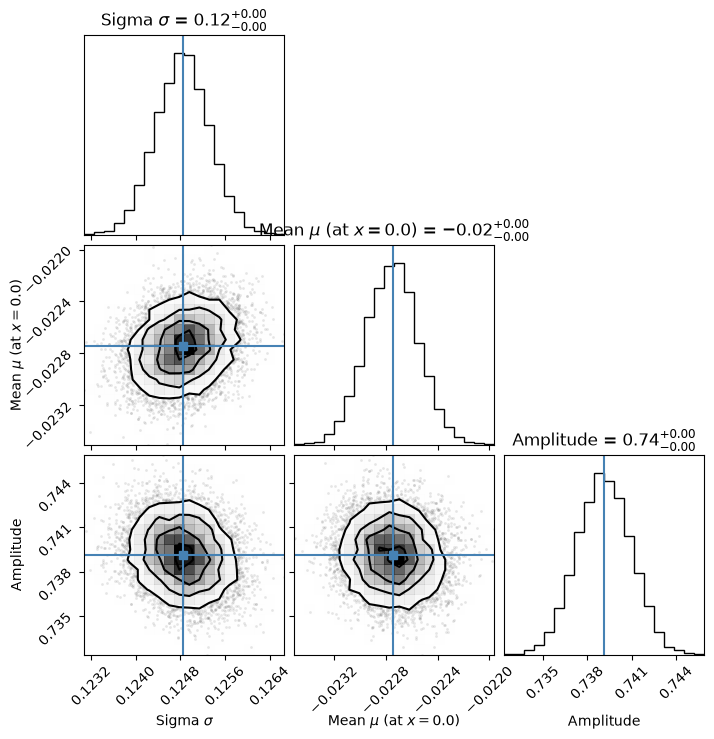

Median sigma: 0.125, mean: -0.023, amplitude: 0.739
m bin:  [7, 9]
z bin:  [8.5, 9.5]
Number of gals in bin:  191
Guesses: sig = 0.290, mean = -0.009, amp = 1.079


100%|██████████| 5000/5000 [00:07<00:00, 688.70it/s]


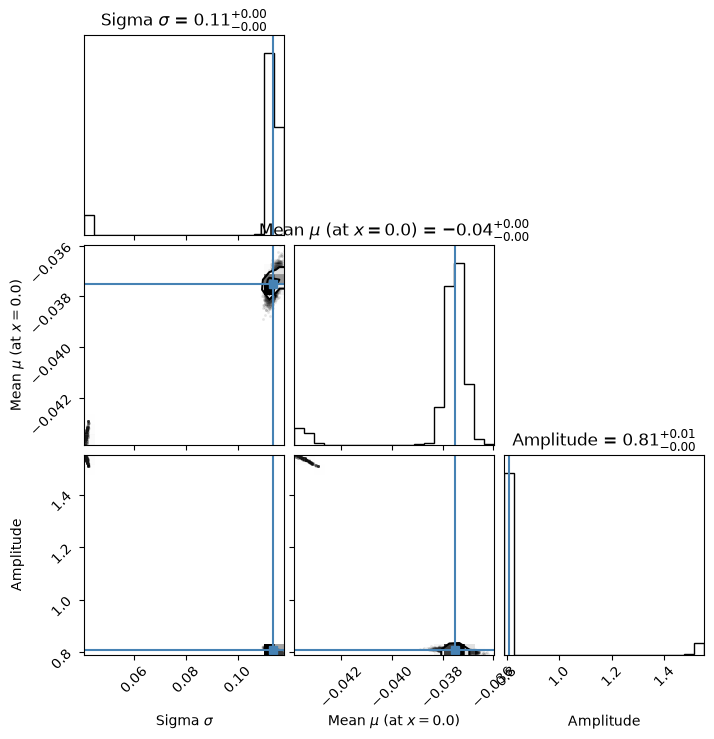

Median sigma: 0.114, mean: -0.038, amplitude: 0.808
m bin:  [7, 9]
z bin:  [9.5, 10.5]
Number of gals in bin:  116
Guesses: sig = 0.460, mean = 0.003, amp = 1.120


100%|██████████| 5000/5000 [00:06<00:00, 827.97it/s]


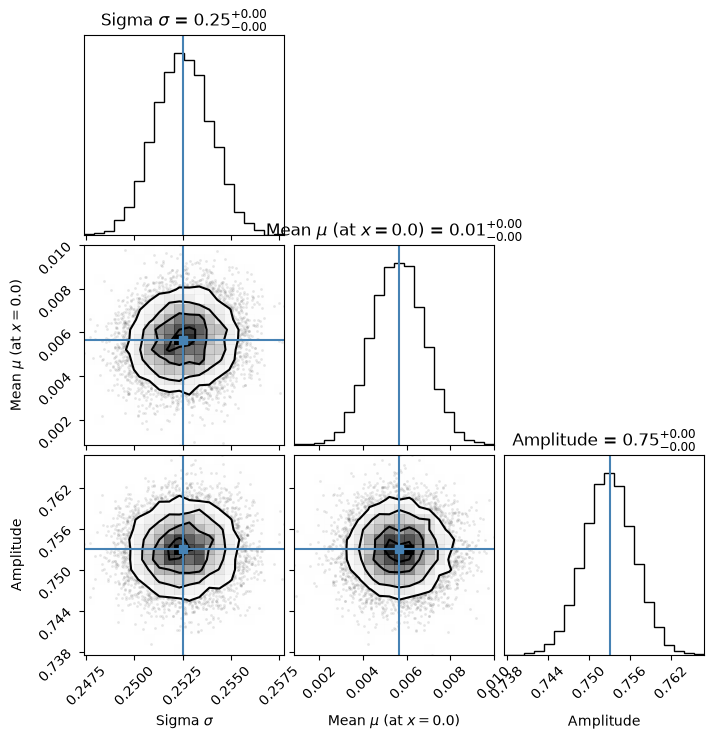

Median sigma: 0.253, mean: 0.006, amplitude: 0.753
m bin:  [7, 9]
z bin:  [10.5, 11.5]
Number of gals in bin:  82
Guesses: sig = 0.609, mean = 0.012, amp = 1.119


100%|██████████| 5000/5000 [00:06<00:00, 795.55it/s]


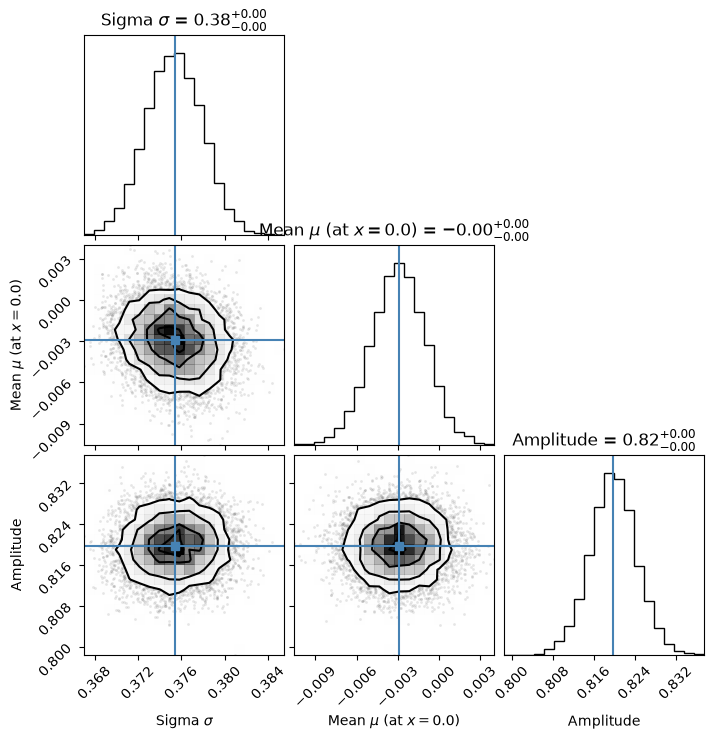

Median sigma: 0.375, mean: -0.003, amplitude: 0.820
m bin:  [7, 9]
z bin:  [11.5, 13.5]
Number of gals in bin:  62
Guesses: sig = 0.516, mean = 0.030, amp = 1.007


100%|██████████| 5000/5000 [00:06<00:00, 805.22it/s]


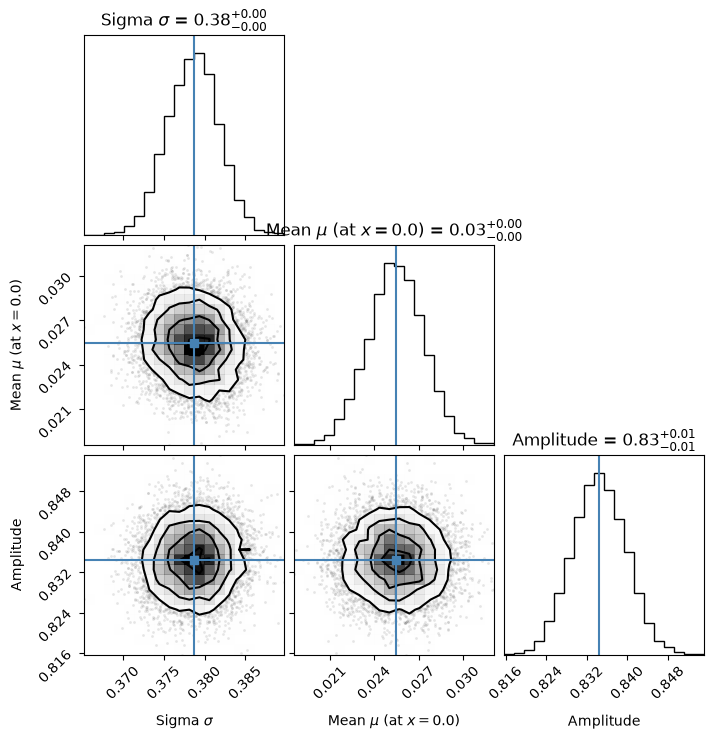

Median sigma: 0.379, mean: 0.025, amplitude: 0.834
m bin:  [6, 7]
z bin:  [6.5, 7.5]
Number of gals in bin:  206
Guesses: sig = 0.197, mean = -0.018, amp = 1.089


100%|██████████| 5000/5000 [00:06<00:00, 805.53it/s]


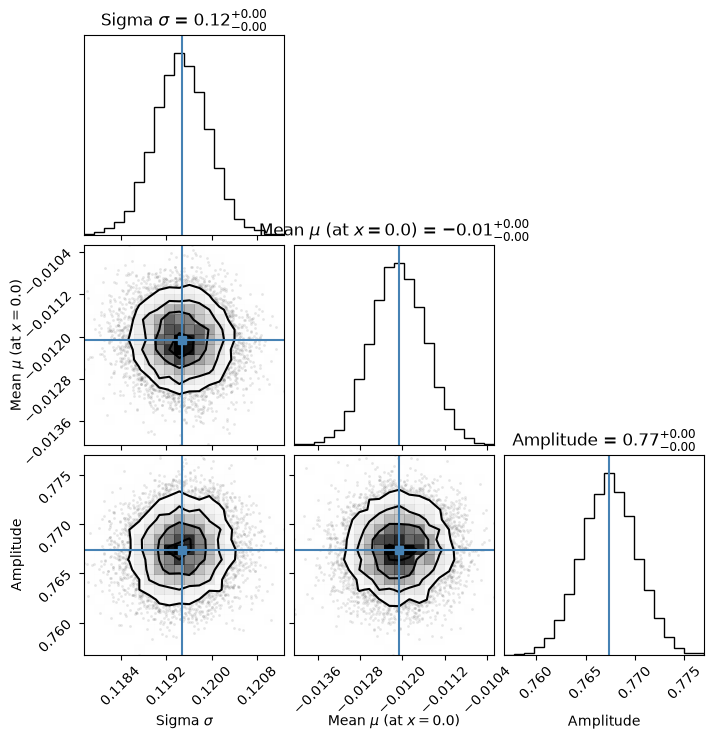

Median sigma: 0.119, mean: -0.012, amplitude: 0.767
m bin:  [6, 7]
z bin:  [7.5, 8.5]
Number of gals in bin:  60
Guesses: sig = 0.200, mean = -0.019, amp = 1.081


100%|██████████| 5000/5000 [00:06<00:00, 723.26it/s]


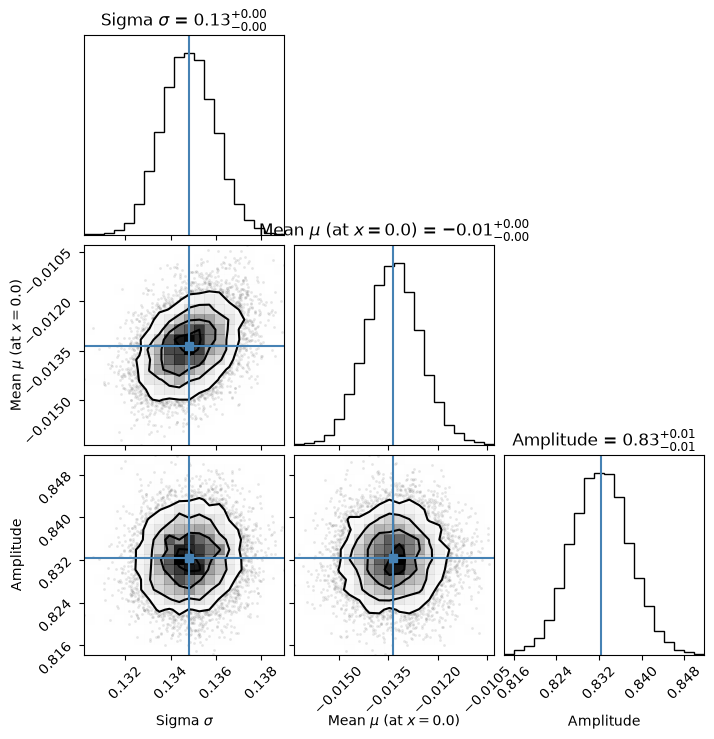

Median sigma: 0.135, mean: -0.013, amplitude: 0.832
m bin:  [6, 7]
z bin:  [8.5, 9.5]
Number of gals in bin:  29
Guesses: sig = 0.255, mean = -0.038, amp = 1.081


100%|██████████| 5000/5000 [00:06<00:00, 766.92it/s]


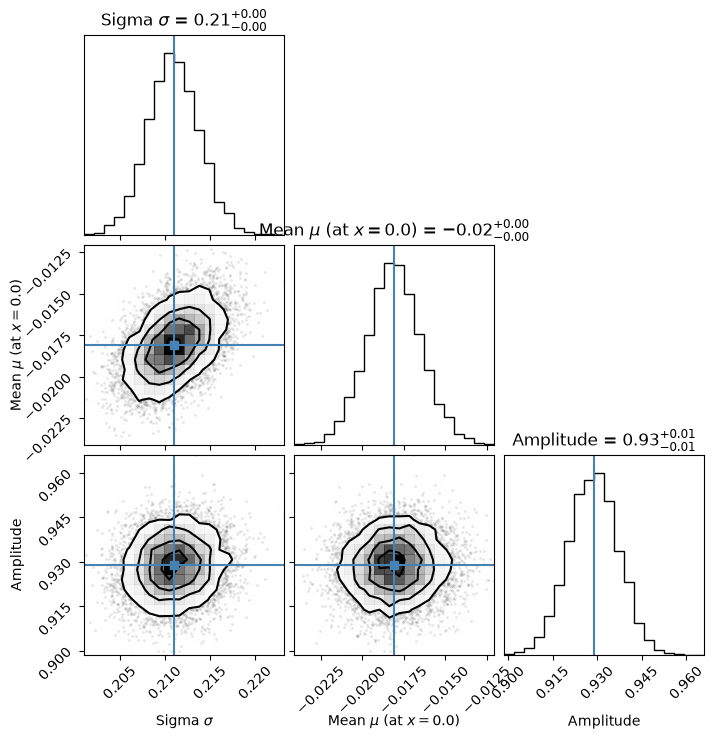

Median sigma: 0.211, mean: -0.018, amplitude: 0.929
m bin:  [6, 7]
z bin:  [9.5, 10.5]
Number of gals in bin:  3
Guesses: sig = 0.988, mean = -0.108, amp = 1.411


100%|██████████| 5000/5000 [00:06<00:00, 804.53it/s]


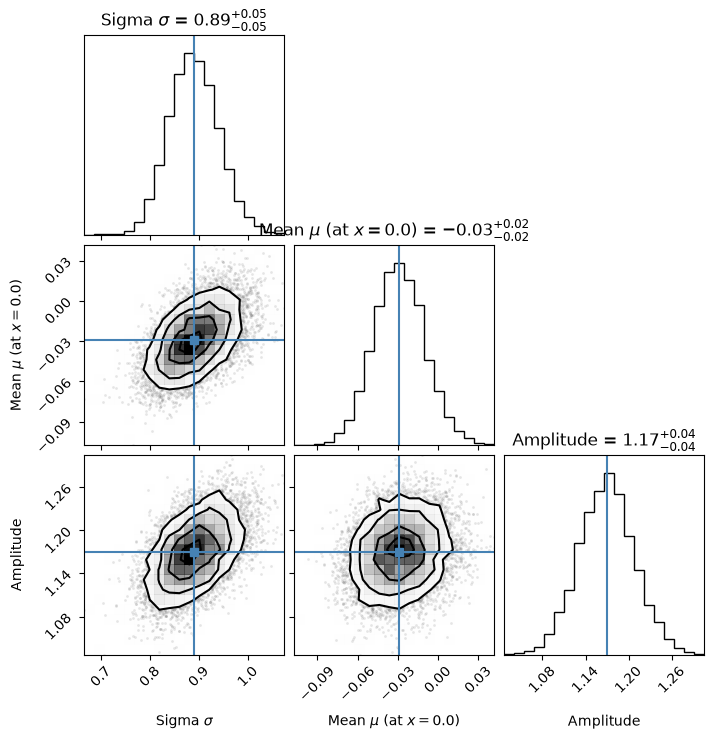

Median sigma: 0.889, mean: -0.029, amplitude: 1.170
m bin:  [6, 7]
z bin:  [10.5, 11.5]
Number of gals in bin:  4
Guesses: sig = 0.294, mean = -0.050, amp = 1.010


100%|██████████| 5000/5000 [00:06<00:00, 824.43it/s]


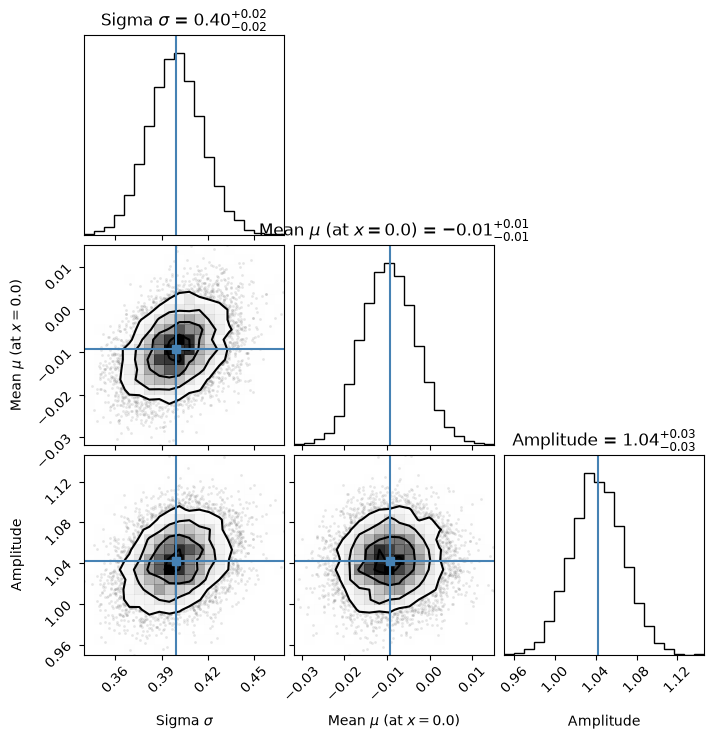

Median sigma: 0.399, mean: -0.009, amplitude: 1.042
m bin:  [6, 7]
z bin:  [11.5, 13.5]
Number of gals in bin:  1
Guesses: sig = 0.753, mean = -0.378, amp = 2.196


100%|██████████| 5000/5000 [00:05<00:00, 848.11it/s]


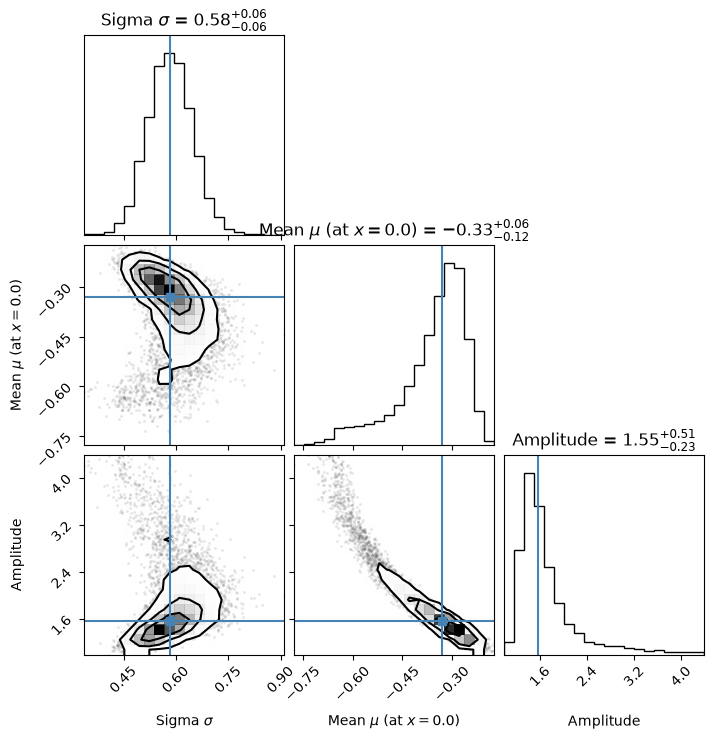

Median sigma: 0.584, mean: -0.330, amplitude: 1.554


<Figure size 640x480 with 0 Axes>

In [6]:
if __name__ == "__main__":

    with fits.open('/raid/scratch/work/alberttg/Masters_project/Data_products/First_sample_table.fits') as hdu:

        sample_table = hdu[1].data
    sample_table = Table(sample_table)

    SFH_models = ["Bagpipes_sfh_cont_bursty_zEAZYsfhzblueagn_3.0,10.0Myr_Calzetti_log_10_Z_log_10_BPASS_zfix"]

    get_posterior(sample_table, SFH_models[0])